In [11]:
!pip -q install "gymnasium[toy-text]>=1.1,<2" pygame imageio reportlab

In [12]:
import os
from pathlib import Path
import gymnasium as gym

os.environ["SDL_VIDEODRIVER"] = "dummy"  # make offscreen rendering work in Colab
PROJECT = Path("/content/Taxi_Q_Learning_Colab_Project")
PROJECT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)

env = gym.make("Taxi-v4")
state, info = env.reset(seed=42)
print("Environment:", env.spec.id)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Starting state:", state)
print("Initial state (text rendering):\n", env.unwrapped.render() if env.render_mode == 'ansi' else "Use GIF cell for RGB rendering")
print("Project folder:", PROJECT)
env.close()

Environment: Taxi-v4
Observation space: Discrete(500)
Action space: Discrete(6)
Starting state: 386
Initial state (text rendering):
 Use GIF cell for RGB rendering
Project folder: /content/Taxi_Q_Learning_Colab_Project


## Part 3. Implement Q-Learning from scratch

We learn a numeric table `Q[state, action]` of shape **500 × 6**, initialized to zero. No pretrained weights, stable-baselines packages, or built-in RL trainers are used.

### Update rule

\[
Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma\max_{a'}Q(s',a') - Q(s,a)\right]
\]

- **Learning rate `α`** controls how much new information replaces old estimates.
- **Discount factor `γ`** controls the value of future rewards.
- **Exploration `ε`** chooses a random action with probability ε; otherwise, the agent chooses a maximum-Q action.
- Exploration decreases from `1.0` to `0.05` for the first 80% of episodes.
- Only `terminated=True` zeroes the future-value term. `truncated=True` merely ends the rollout.

The following cell writes **agent.py** directly to your Colab project folder.

In [13]:
%%writefile agent.py
"""Tabular Q-learning, implemented from scratch for Gymnasium Taxi-v4."""
from dataclasses import dataclass
import numpy as np
import gymnasium as gym

ENV_ID = "Taxi-v4"


@dataclass
class TrainConfig:
    episodes: int = 20_000
    alpha: float = 0.7
    gamma: float = 0.95
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    decay_fraction: float = 0.80
    seed: int = 42


def epsilon_at(episode: int, config: TrainConfig) -> float:
    """Decay epsilon linearly, then keep the exploration floor."""
    fraction = min(1.0, episode / max(1, config.episodes * config.decay_fraction))
    return config.epsilon_start + fraction * (config.epsilon_end - config.epsilon_start)


def train_q_learning(config: TrainConfig, verbose: bool = True):
    """Learn Q(s,a) without pretrained libraries or environment action masks."""
    env = gym.make(ENV_ID)
    rng = np.random.default_rng(config.seed)
    q = np.zeros((env.observation_space.n, env.action_space.n), dtype=np.float64)
    rewards, lengths, successes = [], [], []
    log_every = max(1, config.episodes // 10)

    try:
        for ep in range(config.episodes):
            state, _ = env.reset(seed=config.seed + ep)
            epsilon = epsilon_at(ep, config)
            total_reward, episode_length, succeeded = 0.0, 0, False

            while True:
                if rng.random() < epsilon:
                    action = int(rng.integers(env.action_space.n))
                else:
                    best = np.flatnonzero(q[state] == q[state].max())
                    action = int(rng.choice(best))

                next_state, reward, terminated, truncated, _ = env.step(action)
                # Time-limit truncation is NOT an MDP terminal state:
                # bootstrap at truncation; don't bootstrap at termination.
                target = reward if terminated else reward + config.gamma * q[next_state].max()
                q[state, action] += config.alpha * (target - q[state, action])

                total_reward += float(reward)
                episode_length += 1
                state = next_state
                if terminated or truncated:
                    succeeded = bool(terminated)  # Taxi terminates upon successful delivery
                    break

            rewards.append(total_reward)
            lengths.append(episode_length)
            successes.append(int(succeeded))

            if verbose and ((ep + 1) % log_every == 0 or ep == 0):
                window = min(ep + 1, 250)
                print(f"Episode {ep+1:>6}/{config.episodes} | "
                      f"mean reward (last {window}): {np.mean(rewards[-window:]):>7.2f} | "
                      f"success: {100*np.mean(successes[-window:]):>5.1f}% | "
                      f"epsilon: {epsilon:.3f}")
    finally:
        env.close()

    return q, {
        "episode": np.arange(1, config.episodes + 1),
        "reward": np.array(rewards),
        "steps": np.array(lengths),
        "success": np.array(successes),
    }


def evaluate_policy(q_table=None, episodes: int = 100, seed: int = 10_000, random_policy=False):
    """Evaluate with exploration turned off, using the same fixed initial states."""
    env = gym.make(ENV_ID)
    rng = np.random.default_rng(seed + 100)
    rewards, lengths, successes = [], [], []
    try:
        for ep in range(episodes):
            state, _ = env.reset(seed=seed + ep)
            total_reward, length = 0.0, 0
            while True:
                if random_policy:
                    action = int(rng.integers(env.action_space.n))
                else:
                    action = int(np.argmax(q_table[state]))
                state, reward, terminated, truncated, _ = env.step(action)
                total_reward += float(reward)
                length += 1
                if terminated or truncated:
                    rewards.append(total_reward)
                    lengths.append(length)
                    successes.append(int(terminated))
                    break
    finally:
        env.close()

    return {
        "mean_reward": float(np.mean(rewards)),
        "reward_std": float(np.std(rewards)),
        "success_rate": float(np.mean(successes)),
        "mean_steps": float(np.mean(lengths)),
        "episodes": int(episodes),
    }

Overwriting agent.py


## Part 3b. Save the visualization, GIF, and PDF report utilities

In [14]:
%%writefile utils.py
"""Plots, GIF creation, and PDF report for a complete RL submission."""
import os
from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import imageio.v2 as imageio
import gymnasium as gym

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import cm
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table,
                                TableStyle, Image, PageBreak, KeepTogether)


def rolling_mean(values, window=250):
    return pd.Series(values).rolling(window, min_periods=1).mean().to_numpy()


def plot_training(history, output_path):
    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    x = history["episode"]
    axes[0].plot(x, rolling_mean(history["reward"]), label="Rolling mean reward (250)")
    axes[0].set_ylabel("Reward")
    axes[0].set_title("Q-Learning Convergence on Taxi-v4")
    axes[0].grid(alpha=0.25)
    axes[0].legend()
    axes[1].plot(x, 100 * rolling_mean(history["success"]), label="Rolling success (250)")
    axes[1].set_ylabel("Success rate (%)")
    axes[1].set_xlabel("Training episode")
    axes[1].set_ylim(-3, 103)
    axes[1].grid(alpha=0.25)
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=170, bbox_inches="tight")
    plt.close(fig)


def plot_sensitivity(df, output_path):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, parameter, title in zip(axes, ["alpha", "gamma"], ["Learning rate", "Discount factor"]):
        subset = df[df["parameter"] == parameter].sort_values("value")
        ax.plot(subset["value"].to_numpy(), 100 * subset["success_rate"].to_numpy(), "o-", label="Success")
        ax.set_xlabel(title)
        ax.set_ylabel("Success rate (%)")
        ax.set_ylim(-3, 103)
        ax.grid(alpha=0.25)
    fig.suptitle("Hyperparameter Sensitivity (Same 100 Evaluation Seeds)")
    fig.tight_layout()
    fig.savefig(output_path, dpi=170, bbox_inches="tight")
    plt.close(fig)


def save_success_gif(q_table, output_path, seed_start=50_000, max_trials=200, fps=3):
    """Find a successful greedy rollout; save actual Gymnasium RGB frames."""
    os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
    env = gym.make("Taxi-v4", render_mode="rgb_array")
    try:
        for trial in range(max_trials):
            state, _ = env.reset(seed=seed_start + trial)
            frames = [env.render()]
            total_reward = 0.0
            for step in range(200):
                action = int(np.argmax(q_table[state]))
                state, reward, terminated, truncated, _ = env.step(action)
                total_reward += float(reward)
                frames.append(env.render())
                if terminated or truncated:
                    if terminated:
                        imageio.mimsave(output_path, [np.asarray(frame) for frame in frames], duration=1/fps, loop=0)
                        return {"seed": seed_start + trial, "reward": total_reward, "steps": step + 1,
                                "frames": len(frames)}
                    break
    finally:
        env.close()
    raise RuntimeError("No successful greedy trajectory found in 200 seeds; try more training episodes.")


def create_report(path, config, train_history, results, sensitivity_df, plot_training_path, plot_sensitivity_path, gif_info):
    """Generate a report with REAL run results, capped to four pages."""
    report_path = Path(path)
    stylesheet = getSampleStyleSheet()
    stylesheet.add(ParagraphStyle(name="MainTitleX", parent=stylesheet["Title"], fontSize=18, leading=22,
                                  spaceAfter=12, alignment=TA_CENTER, textColor=colors.HexColor("#12304a")))
    stylesheet.add(ParagraphStyle(name="HeadingX", parent=stylesheet["Heading2"], fontSize=11,
                                  spaceBefore=8, spaceAfter=5, textColor=colors.HexColor("#14436a")))
    stylesheet.add(ParagraphStyle(name="BodyX", parent=stylesheet["BodyText"], fontSize=9, leading=13,
                                  spaceAfter=5))
    stylesheet.add(ParagraphStyle(name="SmallX", parent=stylesheet["BodyText"], fontSize=8, leading=10))
    story = []

    def p(s, style="BodyX"):
        story.append(Paragraph(str(s), stylesheet[style]))

    def h(s):
        p(s, "HeadingX")

    def table(rows, widths=None):
        t = Table(rows, colWidths=widths, hAlign="LEFT", repeatRows=1)
        t.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e7eff6")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.HexColor("#17344a")),
            ("GRID", (0, 0), (-1, -1), 0.35, colors.HexColor("#d4dce5")),
            ("FONTSIZE", (0, 0), (-1, -1), 8),
            ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
            ("TOPPADDING", (0, 0), (-1, -1), 5),
            ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ]))
        story.append(t)
        story.append(Spacer(1, 9))

    p("Custom Reinforcement Learning Agent", "MainTitleX")
    p("Topics in AI | Assignment I (CLO-I) | Taxi-v4 using Q-Learning", "SmallX")
    h("1. Problem Description")
    p("Taxi-v4 is a discrete 5 x 5 navigation problem. The taxi must travel to one of four passenger locations, "
      "pick up the passenger, and deliver them to the indicated destination. "
      "The observation is an encoded integer with 500 possible states: taxi row (5), taxi column (5), "
      "passenger location (5, including inside taxi), and destination (4). There are 6 actions: "
      "south, north, east, west, pickup, and dropoff.")
    p("The environment gives -1 per ordinary time step, -10 for an illegal pickup/dropoff, and +20 for correct "
      "delivery. Success means the episode terminates after delivery; a 200-step limit truncates incomplete episodes.")
    h("2. Methodology")
    p("A tabular Q-learning agent was implemented from scratch. At each step, the epsilon-greedy policy either "
      "explores a uniformly sampled action or exploits a maximum-Q action. The update is:")
    p("<b>Q(s,a) &lt;- Q(s,a) + alpha [r + gamma max Q(s',a') - Q(s,a)]</b>.")
    p("For a true terminal transition, the bootstrap term is zero. At a time-limit truncation, the learner "
      "still bootstraps, but stops the episode. Exploration decreases linearly toward its floor.")
    p("Implementation: <b>agent.py</b> contains training, exploration, and evaluation; <b>utils.py</b> produces "
      "plots, the real RGB-rendered GIF, and this report; <b>main.py</b> runs and exports the experiment. "
      "Only NumPy is used to represent and update the learned Q-values.")
    h("3. Experimental Setup")
    table([
        ["Setting", "Value", "Setting", "Value"],
        ["Environment", "Taxi-v4", "Episodes", str(config.episodes)],
        ["Learning rate (alpha)", f"{config.alpha}", "Discount (gamma)", f"{config.gamma}"],
        ["Start epsilon", f"{config.epsilon_start}", "End epsilon", f"{config.epsilon_end}"],
        ["Decay fraction", f"{config.decay_fraction}", "Random seed", f"{config.seed}"],
        ["Eval episodes", str(results["trained"]["episodes"]), "Q-table shape", "500 x 6"],
    ], widths=[120, 95, 120, 95])
    story.append(PageBreak())

    h("4. Results: Convergence")
    story.append(Image(str(plot_training_path), width=16.4*cm, height=11.5*cm))
    early_window = min(250, len(train_history["reward"]))
    first_avg = float(np.mean(train_history["reward"][:early_window]))
    final_avg = float(np.mean(train_history["reward"][-early_window:]))
    p(f"Average training reward over the first {early_window} episodes was <b>{first_avg:.2f}</b>; "
      f"over the last {early_window} it was <b>{final_avg:.2f}</b>. "
      "The rolling curves indicate whether learning stabilized and how reliably the taxi completes trips.")
    h("5. Evaluation Against Random Policy")
    table([
        ["Policy", "Mean reward", "Success", "Mean steps"],
        ["Untrained random", f'{results["random"]["mean_reward"]:.2f}',
         f'{100*results["random"]["success_rate"]:.1f}%', f'{results["random"]["mean_steps"]:.1f}'],
        ["Trained greedy", f'{results["trained"]["mean_reward"]:.2f}',
         f'{100*results["trained"]["success_rate"]:.1f}%', f'{results["trained"]["mean_steps"]:.1f}'],
    ], widths=[145, 100, 90, 95])
    p("Both policies use the same 100 evaluation starting seeds. No epsilon-greedy exploration is used for "
      "the trained policy during evaluation. Success is the proportion ending in legal passenger delivery.")
    story.append(PageBreak())

    h("6. Hyperparameter Sensitivity")
    story.append(Image(str(plot_sensitivity_path), width=16.4*cm, height=6.9*cm))
    data_rows = [["Parameter", "Value", "Mean reward", "Success"]]
    for row in sensitivity_df.itertuples(index=False):
        data_rows.append([row.parameter, f"{row.value:g}", f"{row.mean_reward:.2f}", f"{100*row.success_rate:.1f}%"])
    table(data_rows, widths=[125, 75, 120, 110])
    best_row = sensitivity_df.sort_values(["success_rate", "mean_reward"], ascending=False).iloc[0]
    p(f"In the shorter sensitivity runs, the highest ranked setting was <b>{best_row['parameter']}="
      f"{best_row['value']:g}</b> with mean evaluation reward <b>{best_row['mean_reward']:.2f}</b> "
      f"and success rate <b>{100*best_row['success_rate']:.1f}%</b>. "
      "These runs are shorter than the main training run and compare only the listed candidate values.")
    h("7. Discussion and Failure Modes")
    p("Initial episodes can accumulate many negative step rewards and illegal pickup/dropoff penalties. "
      "Training improves through repeated state-action updates. Remaining failures can arise from states that "
      "have been visited too rarely during training, too little exploration, or an unfavorable learning rate. "
      "A high success rate alongside shorter routes is evidence of useful learned behavior; the evaluation "
      "scores and plots above are the measured results rather than assumed outcomes.")
    h("8. Conclusion")
    p(f"This implementation learned a tabular policy for Taxi-v4. Across {results['trained']['episodes']} "
      f"evaluation episodes, the trained agent achieved <b>{100*results['trained']['success_rate']:.1f}%</b> "
      f"successful deliveries and mean reward <b>{results['trained']['mean_reward']:.2f}</b>, compared "
      f"with <b>{results['random']['mean_reward']:.2f}</b> for the random baseline. "
      f"A successful demonstrated rollout took <b>{gif_info['steps']}</b> steps. "
      "The exported Q-table and GIF enable direct inspection of the learned behavior.")
    h("Reference")
    p("Farama Foundation. Gymnasium Taxi-v4 documentation: "
      "https://gymnasium.farama.org/environments/toy_text/taxi/", "SmallX")

    def footer(canvas, doc):
        canvas.saveState()
        canvas.setFont("Helvetica", 8)
        canvas.drawCentredString(A4[0]/2, 1.15*cm, f"Topics in AI | Technical Report | Page {doc.page}")
        canvas.restoreState()

    doc = SimpleDocTemplate(str(report_path), pagesize=A4, topMargin=1.65*cm,
                            bottomMargin=1.85*cm, leftMargin=2.0*cm, rightMargin=2.0*cm)
    doc.build(story, onFirstPage=footer, onLaterPages=footer)
    return str(report_path)

Overwriting utils.py


## Part 3c. Save the reproducible main experiment

In [15]:
%%writefile main.py
"""Run the complete Gymnasium Taxi-v4 assignment from Python or Colab."""
import argparse
import json
import os
from pathlib import Path

os.environ.setdefault("SDL_VIDEODRIVER", "dummy")  # headless Colab GIF rendering

import numpy as np
import pandas as pd
from agent import TrainConfig, train_q_learning, evaluate_policy
from utils import plot_training, plot_sensitivity, save_success_gif, create_report


def run(episodes=20_000, sensitivity_episodes=5_000, eval_episodes=100, output_dir="outputs"):
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    config = TrainConfig(episodes=episodes)

    print("\n=== PART 1: Q-LEARNING TRAINING ===")
    q_table, history = train_q_learning(config)
    np.save(out / "q_table.npy", q_table)
    pd.DataFrame(history).to_csv(out / "training_history.csv", index=False)
    plot_training(history, out / "training_curves.png")
    print(f"Saved Q-table: {q_table.shape}, nonzero entries: {np.count_nonzero(q_table)}")

    print("\n=== PART 2: EVALUATION ===")
    trained = evaluate_policy(q_table, episodes=eval_episodes)
    random_baseline = evaluate_policy(episodes=eval_episodes, random_policy=True)
    evaluations = {"trained": trained, "random": random_baseline}
    print("Trained agent:", trained)
    print("Random baseline:", random_baseline)

    print("\n=== PART 3: HYPERPARAMETER SENSITIVITY ===")
    rows = []
    for name, candidates in (("alpha", [0.1, 0.4, 0.7]), ("gamma", [0.8, 0.95, 0.99])):
        for value in candidates:
            varied = TrainConfig(episodes=sensitivity_episodes)
            setattr(varied, name, value)
            q_candidate, _ = train_q_learning(varied, verbose=False)
            scores = evaluate_policy(q_candidate, episodes=eval_episodes)
            rows.append({"parameter": name, "value": value, **scores})
            print(f"{name}={value:<4} => success={scores['success_rate']:.1%}; mean reward={scores['mean_reward']:.2f}")
    sensitivity_df = pd.DataFrame(rows)
    sensitivity_df.to_csv(out / "hyperparameter_results.csv", index=False)
    plot_sensitivity(sensitivity_df, out / "hyperparameter_comparison.png")

    print("\n=== PART 4: SUCCESSFUL DEMONSTRATION GIF ===")
    gif_info = save_success_gif(q_table, out / "trained_taxi.gif")
    print("Successful rollout:", gif_info)

    print("\n=== PART 5: TECHNICAL REPORT ===")
    pdf_path = create_report(
        out / "technical_report.pdf", config, history, evaluations, sensitivity_df,
        out / "training_curves.png", out / "hyperparameter_comparison.png", gif_info
    )
    print("Report written:", pdf_path)

    summary = {"config": vars(config), "evaluation": evaluations,
               "successful_gif": gif_info, "files_generated": sorted(p.name for p in out.iterdir())}
    (out / "results_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print("\nFINISHED. All files are saved under", str(out.resolve()))
    return summary


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Train and evaluate scratch Q-learning on Taxi-v4")
    parser.add_argument("--episodes", type=int, default=20_000)
    parser.add_argument("--sensitivity-episodes", type=int, default=5_000)
    parser.add_argument("--eval-episodes", type=int, default=100)
    parser.add_argument("--output-dir", default="outputs")
    args = parser.parse_args()
    run(args.episodes, args.sensitivity_episodes, args.eval_episodes, args.output_dir)

Overwriting main.py


## Part 4. Installable requirements and reproducibility documentation

The repository must contain the four required Python source files plus the executed notebook, trained Q-table, and a demonstration animation.

In [16]:
%%writefile requirements.txt
gymnasium[toy-text]>=1.1,<2
numpy>=1.24
pandas>=2.0
matplotlib>=3.7
imageio>=2.30
pillow>=10
pygame>=2.5
reportlab>=4.0


Writing requirements.txt


In [17]:
%%writefile README.md
# Custom Q-Learning Agent on Gymnasium Taxi-v3

**Topics in AI, Assignment I (CLO-I)**
**Environment:** `Taxi-v3`
**Algorithm:** tabular Q-Learning implemented from scratch, using NumPy.
**Execution platform:** Google Colab (CPU is sufficient).

## Run in Google Colab (recommended)
1. Open [Google Colab](https://colab.research.google.com/).
2. Upload `Taxi_Q_Learning_Colab.ipynb` using **File > Upload notebook**.
3. Choose **Runtime > Run all**. Internet is required only to install missing Python packages.
4. The notebook creates its source files, trains the model, evaluates the agent, produces figures, saves a real Gymnasium-rendered GIF, and generates a measured technical report.
5. Download the ZIP built at the end, and push the extracted project to a new GitHub repository.

## Run as a Python project
```bash
pip install -r requirements.txt
python main.py --episodes 20000 --sensitivity-episodes 5000 --eval-episodes 100
```

For a faster smoke test (not recommended for your final report):
```bash
python main.py --episodes 2000 --sensitivity-episodes 1000 --eval-episodes 20
```

## Generated deliverables
Running the notebook or script creates `outputs/`:

- `q_table.npy`: trained Q(s,a), shape 500 x 6
- `trained_taxi.gif`: **actual rendered successful** agent trajectory
- `training_curves.png`: reward convergence and success curve
- `hyperparameter_comparison.png`: learning-rate and discount-factor sensitivity
- `training_history.csv`, `hyperparameter_results.csv`: experiment data
- `results_summary.json`: reproducible measurements
- `technical_report.pdf`: automatically written with run-specific measurements (maximum 4 pages)

## The Q-Learning update

`Q(s,a) = Q(s,a) + alpha * (reward + gamma * max_a' Q(s',a') - Q(s,a))`

For true terminal transitions, the bootstrap term is zero. We do not use pre-trained agents or built-in RL algorithms.

## Taxi-v3 environment

- States: 500 encoded discrete observations (taxi row/col, passenger position, destination).
- Actions: 6 (south/north/east/west/pickup/dropoff).
- Rewards: -1 per ordinary step, -10 for illegal pickup/dropoff, +20 for correct delivery.
- Successful delivery terminates an episode, otherwise a time limit truncates it.

Official reference: https://gymnasium.farama.org/environments/toy_text/taxi/

## Academic usage note
Training and evaluation scores should be taken from the outputs of your own completed run. The report generator inserts the measured values. Add your name, roll number, and any instructor-required formatting before you submit.


Overwriting README.md


In [18]:
%%writefile .gitignore
__pycache__/
.ipynb_checkpoints/
*.pyc
.DS_Store


Writing .gitignore


## Part 5. Train, evaluate, compare, render GIF, and generate PDF

The main run uses **20,000 Q-learning episodes**. For a meaningful comparison, it also evaluates:

1. **Untrained random policy vs. trained greedy policy** using the same 100 initial seeds.
2. **Learning rate sensitivity:** `α = 0.1, 0.4, 0.7`.
3. **Discount factor sensitivity:** `γ = 0.80, 0.95, 0.99`.

Each sensitivity setting receives 5,000 training episodes, followed by 100 evaluation episodes. Output files are saved to `outputs/` and the report uses the actual generated measurements.

In [19]:
from main import run

results = run(
    episodes=20_000,
    sensitivity_episodes=5_000,
    eval_episodes=100,
    output_dir="outputs"
)


=== PART 1: Q-LEARNING TRAINING ===
Episode      1/20000 | mean reward (last 1): -776.00 | success:   0.0% | epsilon: 1.000
Episode   2000/20000 | mean reward (last 250): -518.44 | success:  59.2% | epsilon: 0.881
Episode   4000/20000 | mean reward (last 250): -203.90 | success: 100.0% | epsilon: 0.763
Episode   6000/20000 | mean reward (last 250):  -98.52 | success: 100.0% | epsilon: 0.644
Episode   8000/20000 | mean reward (last 250):  -60.52 | success: 100.0% | epsilon: 0.525
Episode  10000/20000 | mean reward (last 250):  -31.46 | success: 100.0% | epsilon: 0.406
Episode  12000/20000 | mean reward (last 250):  -12.00 | success: 100.0% | epsilon: 0.288
Episode  14000/20000 | mean reward (last 250):   -2.74 | success: 100.0% | epsilon: 0.169
Episode  16000/20000 | mean reward (last 250):    5.37 | success: 100.0% | epsilon: 0.050
Episode  18000/20000 | mean reward (last 250):    5.18 | success: 100.0% | epsilon: 0.050
Episode  20000/20000 | mean reward (last 250):    5.36 | success:

## Part 6. Display training curves and hyperparameter comparisons

**Interpretation guide:** Successful learning typically produces increasing average reward, improving success rate, and fewer time-limit failures. Inspect the measured trends rather than assuming the results will always be identical.

Training convergence and success rate:


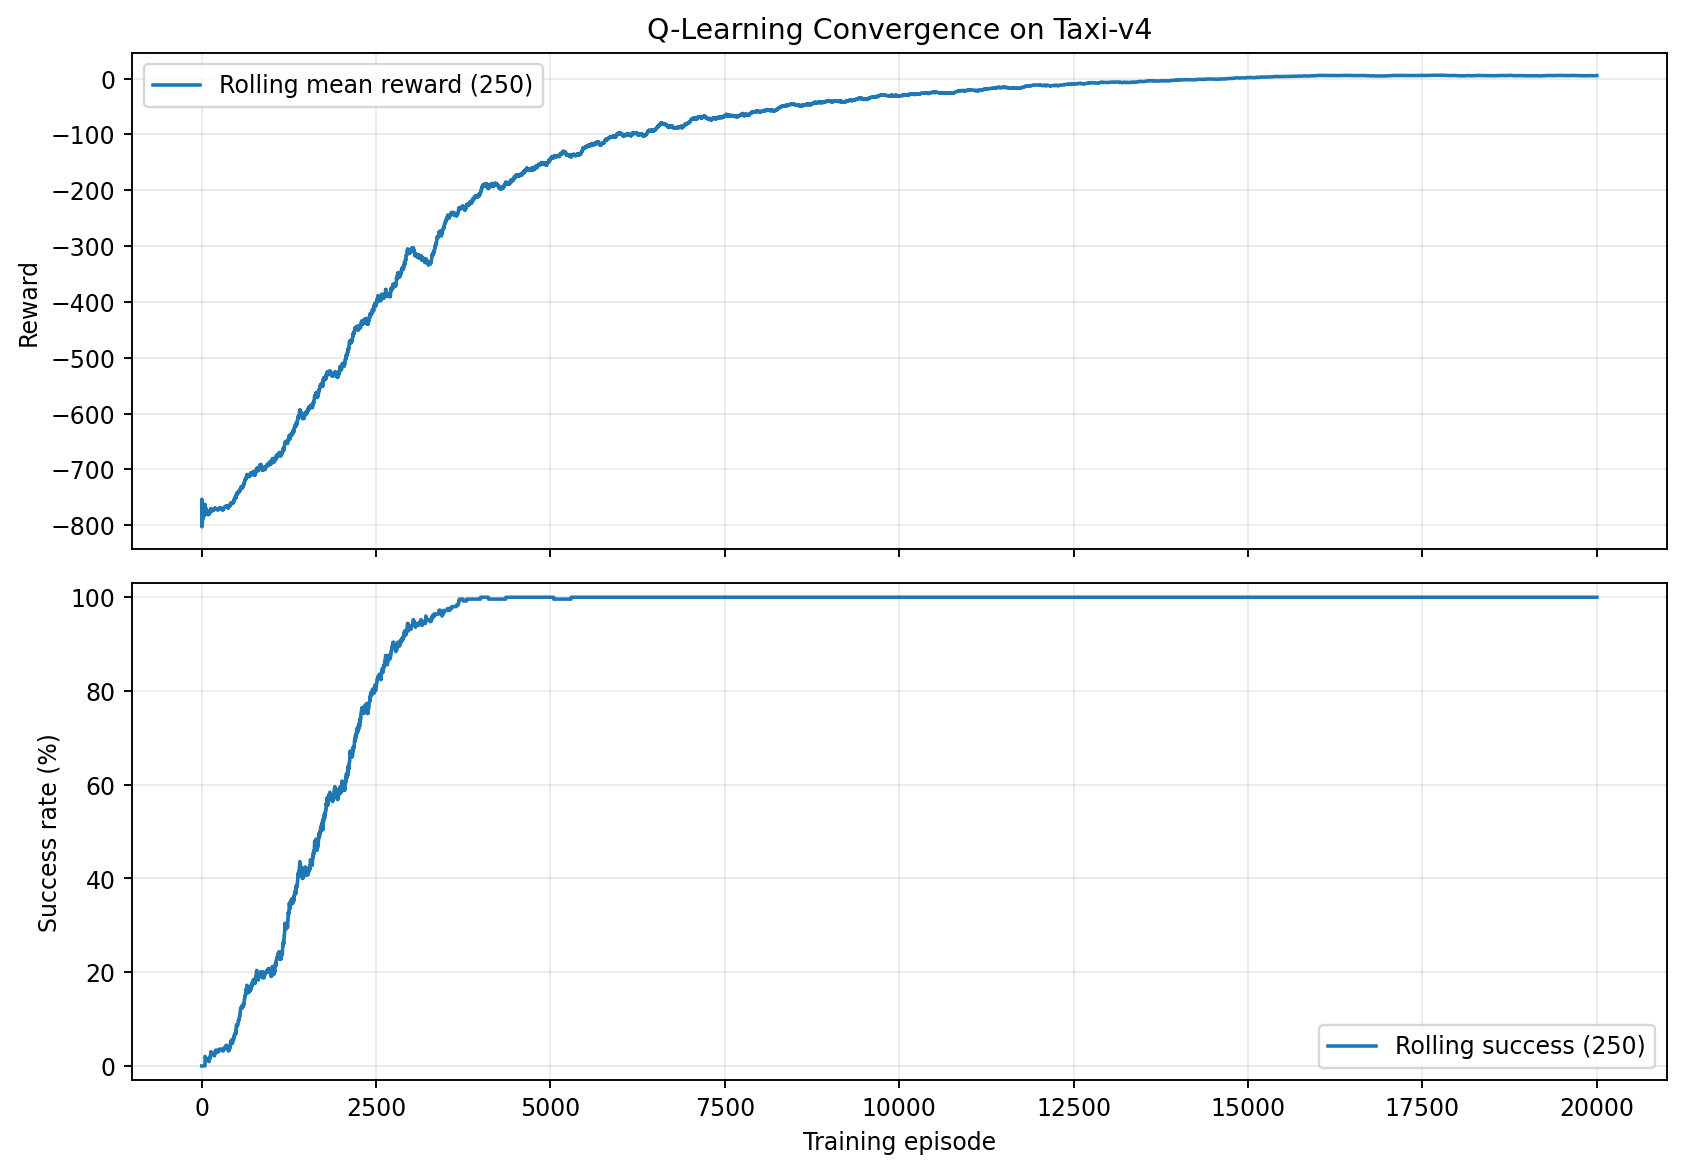

Hyperparameter sensitivity:


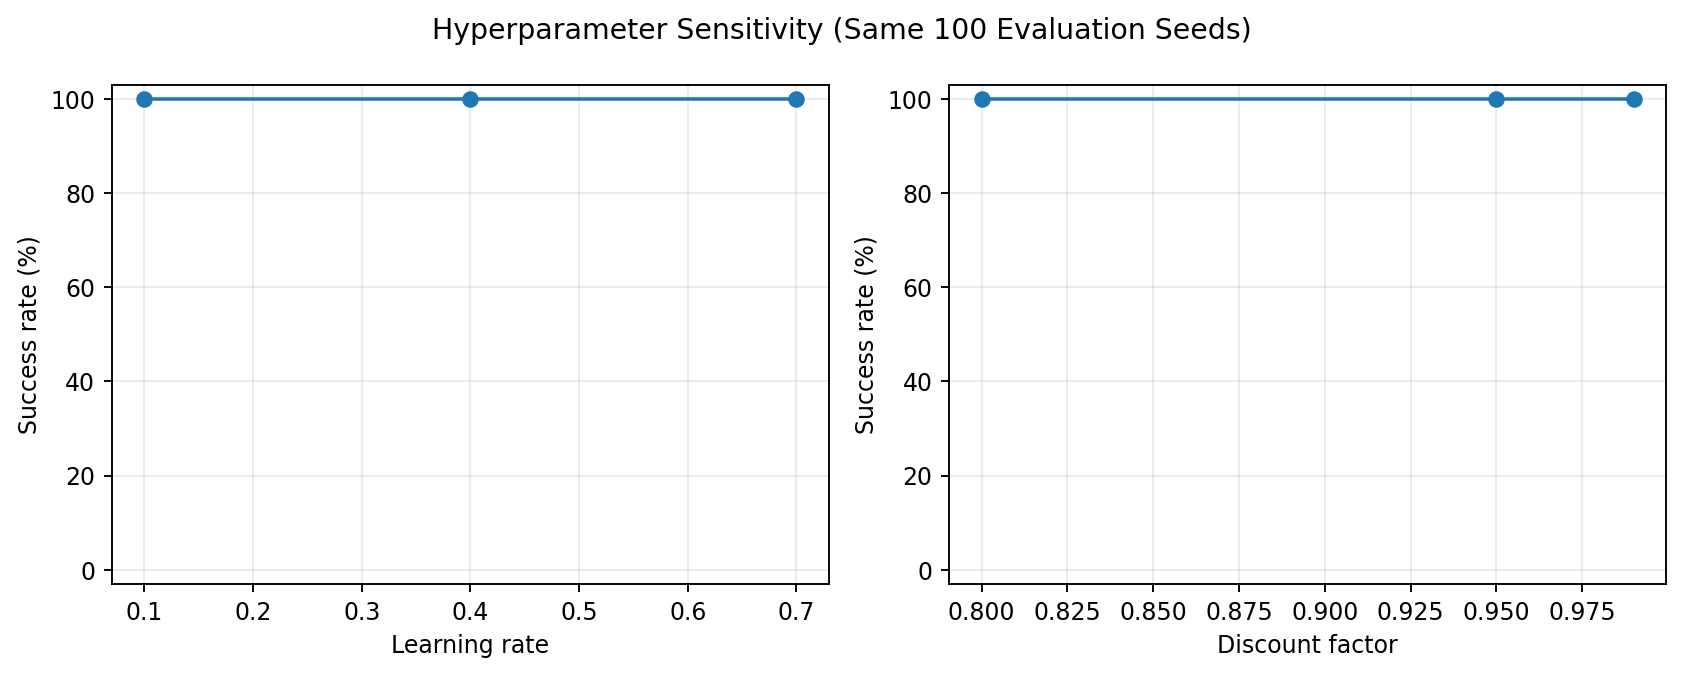

Exact sensitivity metrics:


,parameter,value,mean_reward,reward_std,success_rate,mean_steps,episodes
0,alpha,0.10,8.05,2.507489,1.0,12.95,100
1,alpha,0.40,8.05,2.507489,1.0,12.95,100
2,alpha,0.70,8.05,2.507489,1.0,12.95,100
3,gamma,0.80,8.05,2.507489,1.0,12.95,100
4,gamma,0.95,8.05,2.507489,1.0,12.95,100
5,gamma,0.99,8.05,2.507489,1.0,12.95,100


Evaluation results:


,mean_reward,reward_std,success_rate,mean_steps,episodes
trained,8.05,2.507489,1.00,12.95,100.0
random,-768.47,78.236750,0.01,198.98,100.0


In [20]:
from IPython.display import display, Image as DisplayImage
import pandas as pd

print("Training convergence and success rate:")
display(DisplayImage(filename="outputs/training_curves.png"))
print("Hyperparameter sensitivity:")
display(DisplayImage(filename="outputs/hyperparameter_comparison.png"))
print("Exact sensitivity metrics:")
display(pd.read_csv("outputs/hyperparameter_results.csv"))
print("Evaluation results:")
display(pd.DataFrame(results["evaluation"]).T)

## Part 7. Watch the trained taxi deliver a passenger

The animation contains frames from **Gymnasium's `render_mode='rgb_array'`**, not a simulated or pre-made animation. The recorder tries different reproducible start states until the greedy policy achieves a successful delivery.

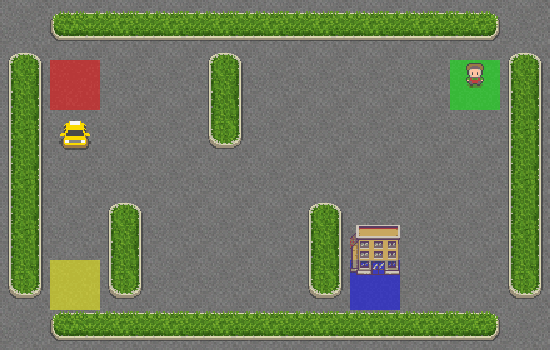

In [21]:
display(DisplayImage(filename="outputs/trained_taxi.gif"))

## Part 8. Confirm Q-table and saved artifacts

This verifies the Q-table can be loaded, shows which files have been produced, and checks the report's page count.

In [22]:
import numpy as np
import os
from pathlib import Path

q_loaded = np.load("outputs/q_table.npy")
print("Q-table shape:", q_loaded.shape)
print("Nonzero Q-values:", np.count_nonzero(q_loaded))
print("Saved deliverables:")
for item in sorted(Path("outputs").iterdir()):
    print(f"  {item.name:34} {item.stat().st_size/1024:10.1f} KB")

try:
    import fitz
    with fitz.open("outputs/technical_report.pdf") as pdf:
        print("Technical report pages:", len(pdf))
        assert len(pdf) <= 4, "Report longer than 4 pages; adjust report layout before submitting."
except ImportError:
    print("PDF generated. Optional PyMuPDF not installed, so page count was not checked here.")

Q-table shape: (500, 6)
Nonzero Q-values: 2400
Saved deliverables:
  hyperparameter_comparison.png            49.4 KB
  hyperparameter_results.csv                0.4 KB
  q_table.npy                              23.6 KB
  results_summary.json                      0.8 KB
  technical_report.pdf                    184.6 KB
  trained_taxi.gif                        244.8 KB
  training_curves.png                      92.8 KB
  training_history.csv                    316.6 KB
PDF generated. Optional PyMuPDF not installed, so page count was not checked here.
